# IMPLEMENTING A SIMPLIFIED ATTENTION MECHANISM

<div class = "alert alert-success">

Consider the following input sentence, which has already been embedded into 3- dimensional vectors.

We choose a small embedding dimension for illustration purposes to ensure it fits on the page without line breaks:

In [1]:
import torch

In [2]:
inputs = torch.tensor([
   [0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]  # step     (x^6)
])

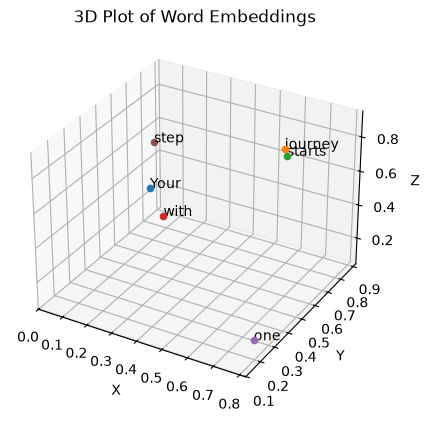

In [3]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Corresponding words
words = ['Your', 'journey', 'starts', 'with', 'one', 'step']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

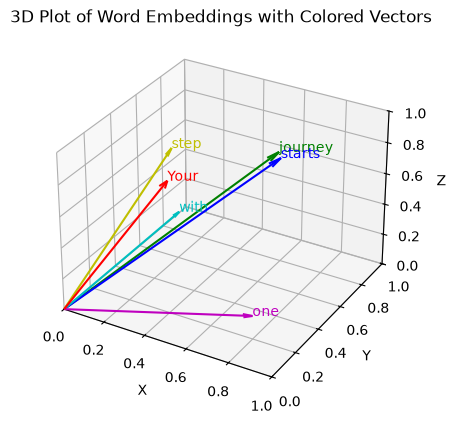

In [4]:
# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings with Colored Vectors')
plt.show()


<div class="alert alert-block alert-info">
    
Each row represents a word, and each column represents an embedding dimension
    
</div>

<div class="alert alert-block alert-info">
    
The second input token serves as the query    
</div>

In [5]:
query = inputs[1] # 2nd input token is the query

attention_Score_2 = torch.empty(inputs.shape[0])


for i,x_i in enumerate(inputs):
    attention_Score_2[i] = torch.dot(x_i,query)
    
print(attention_Score_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


<div class="alert alert-block alert-success">

In the next step, we normalize each of the attention scores that
we computed previously.

</div>

<div class = "alert alert-success">

The main goal behind the normalization is to obtain attention weights that sum up to 1.

This normalization is a convention that is useful for interpretation and for maintaining training stability in an LLM.

Here's a straightforward method for achieving this normalization step:

In [6]:
attention_weights_2_tmp = attention_Score_2 / attention_Score_2.sum()

print("Attention weights : ",attention_weights_2_tmp)
print("Sum : ",attention_weights_2_tmp.sum())

Attention weights :  tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
Sum :  tensor(1.0000)


<div class = "alert alert-info">
In practice, it's more common and advisable to use the softmax function for normalization.

This approach is better at managing extreme values and offers more favorable gradient properties during training.

Below is a basic implementation of the softmax function for normalizing the attention scores:

In [7]:
def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)

attention_weights_2_naive = softmax_naive(attention_Score_2)

print("Attention weights : ",attention_weights_2_naive)
print("Sum : ",attention_weights_2_naive.sum())

Attention weights :  tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum :  tensor(1.)


<div class = "alert alert-info">
As the output shows, the softmax function also meets the objective and normalizes the attention weights such that they sum to 1:

<div class = "alert alert-warning">
In addition, the softmax function ensures that the attention weights are always positive. This makes the output interpretable as probabilities or relative importance, where higher weights indicate greater importance.

<div class = "alert alert-warning">
Note that this naive softmax implementation (softmax_naive) may encounter numerical instability problems, such as overflow and underflow, when dealing with large or small input values.

Therefore, in practice, it's advisable to use the PyTorch implementation of softmax, which has been extensively optimized for performance:

In [8]:
attention_weight_2 = torch.softmax(attention_Score_2,dim=0)
print("Attention weights:", attention_weight_2)
print("Sum:", attention_weight_2.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


<div class = "alert alert-info">
In this case, we can see that it yields the same results as our previous softmax_naive function:

<div class = "alert alert-info">
The context vector z(2)is calculated as a weighted sum of all input vectors.

This involves multiplying each input vector by its corresponding attention weight:

In [9]:
query = inputs[1] # 2nd input token is the query

context_vec_2 = torch.zeros(query.shape)
print(context_vec_2)

for i,x_i in enumerate(inputs): 
    context_vec_2 += attention_weight_2[i]*x_i
    
print(context_vec_2)

tensor([0., 0., 0.])
tensor([0.4419, 0.6515, 0.5683])


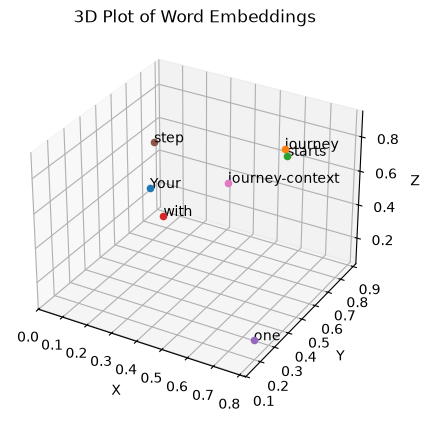

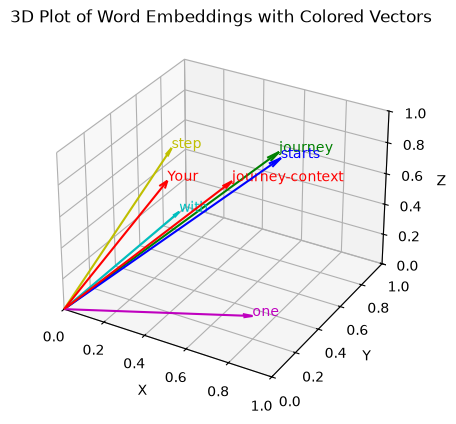

In [10]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55], # step     (x^6)
   [0.4419, 0.6515, 0.5683]]
)

# Corresponding words
words = ['Your', 'journey', 'starts', 'with', 'one', 'step', 'journey-context']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y', 'r']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings with Colored Vectors')
plt.show()

<div class = "alert alert-info">
Now, we can extend this computation to calculate attention weights and context vectors for all inputs.

<div class="alert alert-block alert-success">

First, we add an additional for-loop to compute the
dot products for all pairs of inputs.

</div>

In [11]:
inputs

tensor([[0.4300, 0.1500, 0.8900],
        [0.5500, 0.8700, 0.6600],
        [0.5700, 0.8500, 0.6400],
        [0.2200, 0.5800, 0.3300],
        [0.7700, 0.2500, 0.1000],
        [0.0500, 0.8000, 0.5500],
        [0.4419, 0.6515, 0.5683]])

In [12]:
attention_score = torch.empty(7,7)

for i,x_i in enumerate(inputs,start=0):
    for j,x_j in enumerate(inputs,start=0):  
        attention_score[i,j] = torch.dot(x_i,x_j)
    
print(attention_score)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310, 0.7935],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865, 1.1849],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605, 1.1694],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565, 0.6626],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935, 0.5600],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450, 0.8559],
        [0.7935, 1.1849, 1.1694, 0.6626, 0.5600, 0.8559, 0.9427]])


<div class = "alert alert-info">
Each element in the preceding tensor represents an attention score between each pair of inputs.


<div class = "alert alert-info">
When computing the preceding attention score tensor, we used for-loops in Python.

However, for-loops are generally slow, and we can achieve the same results using matrix multiplication:

In [13]:
inputs.shape

torch.Size([7, 3])

In [14]:
inputs.T.shape

torch.Size([3, 7])

In [15]:
attention_score = inputs @ inputs.T
print(attention_score)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310, 0.7935],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865, 1.1849],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605, 1.1694],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565, 0.6626],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935, 0.5600],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450, 0.8559],
        [0.7935, 1.1849, 1.1694, 0.6626, 0.5600, 0.8559, 0.9427]])


<div class = "alert alert-info">
We now normalize each row so that the values in each row sum to 1:

In [16]:
attention_weight = torch.softmax(attention_score,dim=-1)
print(attention_weight)

tensor([[0.1792, 0.1713, 0.1692, 0.1061, 0.1042, 0.1240, 0.1459],
        [0.1180, 0.2026, 0.1986, 0.1056, 0.0921, 0.1346, 0.1486],
        [0.1184, 0.2017, 0.1981, 0.1058, 0.0943, 0.1332, 0.1485],
        [0.1223, 0.1768, 0.1744, 0.1246, 0.1077, 0.1467, 0.1476],
        [0.1305, 0.1675, 0.1689, 0.1169, 0.1607, 0.1108, 0.1446],
        [0.1180, 0.1861, 0.1813, 0.1211, 0.0842, 0.1615, 0.1478],
        [0.1277, 0.1889, 0.1860, 0.1121, 0.1011, 0.1359, 0.1483]])


<div class = "alert alert-warning">
In the context of using PyTorch, the dim parameter in functions like torch.softmax specifies the dimension of the input tensor along which the function will be computed.

By setting dim=-1, we are instructing the softmax function to apply the normalization along the last dimension of the attn_scores tensor.

If attn_scores is a 2D tensor (for example, with a shape of [rows, columns]), dim=-1 will normalize across the columns so that the values in each row (summing over the column dimension) sum up to 1.

<div class = "alert alert-info">
Let's briefly verify that the rows indeed all sum to 1:

In [17]:
row_2_sum = sum([0.1180, 0.2026, 0.1986, 0.1056, 0.0921, 0.1346, 0.1486])

print("Row 2 sum : ",row_2_sum)
print("All Row sum : ",attention_weight.sum(dim=-1))

Row 2 sum :  1.0001
All Row sum :  tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


<div class = "alert alert-info">
In the third and last step, we now use these attention weights to compute all context vectors via matrix multiplication:

In [18]:
all_context_vector = attention_weight @ inputs
print(all_context_vector)

tensor([[0.4420, 0.6016, 0.5774],
        [0.4419, 0.6515, 0.5683],
        [0.4429, 0.6499, 0.5673],
        [0.4321, 0.6330, 0.5536],
        [0.4635, 0.5997, 0.5326],
        [0.4213, 0.6505, 0.5651],
        [0.4397, 0.6372, 0.5635]])


<div class = "alert alert-info">

We can double-check that the code is correct by comparing the 2nd row with the context vector z(2) calculated previously

In [19]:
print("Previous 2nd context vector:", context_vec_2)

Previous 2nd context vector: tensor([0.4419, 0.6515, 0.5683])


<div class="alert alert-block alert-info">
    
Based on the result, we can see that the previously calculated context_vec_2 matches the
second row in the previous tensor exactly
</div>

<div class = "alert alert-success">
This concludes the code walkthrough of a simple self-attention mechanism.

# IMPLEMENTING SELF ATTENTION WITH TRAINABLE WEIGHTS

In [20]:
import torch

In [21]:
inputs = torch.tensor([
   [0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]  # step     (x^6)
])

<div class = "alert alert-info">
Let's begin by defining a few variables:

<div class = "alert alert-success">

__A.__ The second input element

__B.__ The input embedding size, d=3

__C.__ The output embedding size, d_out=2

In [22]:
# A
x_2 = inputs[1]
# B
d_in = inputs.shape[1]
# C
d_out = 2


<div class = "alert alert-info">
Note that in GPT-like models, the input and output dimensions are usually the same.

But for illustration purposes, to better follow the computation, we choose different input (d_in=3) and output (d_out=2) dimensions here.

<div class = "alert alert-info">
Next, we initialize the three weight matrices Wq, Wk and Wv

In [23]:
torch.manual_seed(123)
w_query = torch.nn.Parameter(torch.rand(d_in,d_out),requires_grad=True)
w_key = torch.nn.Parameter(torch.rand(d_in,d_out),requires_grad=True)
w_value = torch.nn.Parameter(torch.rand(d_in,d_out),requires_grad=True)

In [24]:
print(w_query)

Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]], requires_grad=True)


In [25]:
print(w_key)

Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]], requires_grad=True)


In [26]:
print(w_value)

Parameter containing:
tensor([[0.0756, 0.1966],
        [0.3164, 0.4017],
        [0.1186, 0.8274]], requires_grad=True)


<div class = "alert alert-info">
Note that we are setting requires_grad=False to reduce clutter in the outputs for illustration purposes.

If we were to use the weight matrices for model training, we would set requires_grad=True to update these matrices during model training.

<div class = "alert alert-success">
Next, we compute the query, key, and value vectors as shown earlier

In [27]:
querie_2 = x_2 @ w_query
key_2 = x_2 @ w_key
value_2 = x_2 @ w_value

In [28]:
print(querie_2)

tensor([0.4306, 1.4551], grad_fn=<SqueezeBackward4>)


<div class = "alert alert-warning">
As we can see based on the output for the query, this results in a 2-dimensional vector.

This is because: we set the number of columns of the corresponding weight matrix, via d_out, to 2:

<div class = "alert alert-info">
Even though our temporary goal is to only compute the one context vector z(2), we still require the key and value vectors for all input elements.

This is because they are involved in computing the attention weights with respect to the query q(2)

<div class = "alert alert-info">
We can obtain all keys and values via matrix multiplication:

In [29]:
keys = inputs @ w_key
values = inputs @ w_value
queries = inputs @ w_query 

In [30]:
print("Key shape : ",keys.shape)
print("Value shape : ",values.shape)
print("Querie shape : ",queries.shape)

Key shape :  torch.Size([6, 2])
Value shape :  torch.Size([6, 2])
Querie shape :  torch.Size([6, 2])


<div class = "alert alert-info">
As we can tell from the outputs, we successfully projected the 6 input tokens from a 3D onto a 2D embedding space:

<div class = "alert alert-success">
First, let's compute the attention score ω22

In [31]:
keys_2 = keys[1]
attention_score = querie_2.dot(keys_2)
print(attention_score)

tensor(1.8524, grad_fn=<DotBackward0>)


<div class="alert alert-block alert-success">
Again, we can generalize this computation to all attention scores via matrix multiplication:</div>

In [32]:
attention_score_2 = querie_2 @ keys.T # # All attention scores for given query
print(attention_Score_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [33]:
attention_score = queries @ keys.T
print(attention_score)

tensor([[0.9231, 1.3545, 1.3241, 0.7910, 0.4032, 1.1330],
        [1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440],
        [1.2544, 1.8284, 1.7877, 1.0654, 0.5508, 1.5238],
        [0.6973, 1.0167, 0.9941, 0.5925, 0.3061, 0.8475],
        [0.6114, 0.8819, 0.8626, 0.5121, 0.2707, 0.7307],
        [0.8995, 1.3165, 1.2871, 0.7682, 0.3937, 1.0996]],
       grad_fn=<MmBackward0>)


<div class = "alert alert-info">
We compute the attention weights by scaling the attention scores and using the softmax function we used earlier.

The difference to earlier is that we now scale the attention scores by dividing them by the square root of the embedding dimension of the keys.

Note that taking the square root is mathematically the same as exponentiating by 0.5:

In [34]:
d_keys = keys.shape[-1]
attention_weights_2 = torch.softmax(attention_score_2/d_keys**0.5,dim=-1)
print(attention_weight_2)
print(d_keys)

tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
2


<div class = "alert alert-warning">

## WHY DIVIDE BY SQRT (DIMENSION)

<div class = "alert alert-success">
Reason 1: For stability in learning

The softmax function is sensitive to the magnitudes of its inputs. When the inputs are large, the differences between the exponential values of each input become much more pronounced. This causes the softmax output to become "peaky," where the highest value receives almost all the probability mass, and the rest receive very little.

In attention mechanisms, particularly in transformers, if the dot products between query and key vectors become too large (like multiplying by 8 in this example), the attention scores can become very large. This results in a very sharp softmax distribution, making the model overly confident in one particular "key." Such sharp distributions can make learning unstable,

In [35]:
import torch

# Define the tensor
tensor = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])

# Apply softmax without scaling
softmax_result = torch.softmax(tensor, dim=-1)
print("Softmax without scaling:", softmax_result)

# Multiply the tensor by 8 and then apply softmax
scaled_tensor = tensor * 8
softmax_scaled_result = torch.softmax(scaled_tensor, dim=-1)
print("Softmax after scaling (tensor * 8):", softmax_scaled_result)

Softmax without scaling: tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])
Softmax after scaling (tensor * 8): tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])


<div class = "alert alert-warning">

## BUT WHY SQRT?

<div class = "alert alert-success">
Reason 2: To make the variance of the dot product stable

The dot product of Q and K increases the variance because multiplying two random numbers increases the variance.

The increase in variance grows with the dimension.

Dividing by sqrt (dimension) keeps the variance close to 1

In [36]:
import numpy as np

# Function to compute variance before and after scaling
def compute_variance(dim, num_trials=1000):
    dot_products = []
    scaled_dot_products = []

    # Generate multiple random vectors and compute dot products
    for _ in range(num_trials):
        q = np.random.randn(dim)
        k = np.random.randn(dim)
        
        # Compute dot product
        dot_product = np.dot(q, k)
        dot_products.append(dot_product)
        
        # Scale the dot product by sqrt(dim)
        scaled_dot_product = dot_product / np.sqrt(dim)
        scaled_dot_products.append(scaled_dot_product)
    
    # Calculate variance of the dot products
    variance_before_scaling = np.var(dot_products)
    variance_after_scaling = np.var(scaled_dot_products)

    return variance_before_scaling, variance_after_scaling

# For dimension 5
variance_before_5, variance_after_5 = compute_variance(5)
print(f"Variance before scaling (dim=5): {variance_before_5}")
print(f"Variance after scaling (dim=5): {variance_after_5}")

# For dimension 20
variance_before_100, variance_after_100 = compute_variance(100)
print(f"Variance before scaling (dim=100): {variance_before_100}")
print(f"Variance after scaling (dim=100): {variance_after_100}")



Variance before scaling (dim=5): 5.0708225267632185
Variance after scaling (dim=5): 1.0141645053526436
Variance before scaling (dim=100): 99.47710958588253
Variance after scaling (dim=100): 0.9947710958588252


<div class = "alert alert-info">
We now compute the context vector as a weighted sum over the value vectors.

Here, the attention weights serve as a weighting factor that weighs the respective importance of each value vector.

We can use matrix multiplication to obtain the output in one step:

In [37]:
context_vec_2 = attention_weights_2 @ values
print(context_vec_2)

tensor([0.3061, 0.8210], grad_fn=<SqueezeBackward4>)


<div class = "alert alert-success">
So far, we only computed a single context vector, z(2).

In the next section, we will generalize the code to compute all context vectors in the input sequence, z(1)to z (T)

### IMPLEMENTING A COMPACT SELF ATTENTION PYTHON CLASS

<div class = "alert alert-warning">
In the previous sections, we have gone through a lot of steps to compute the self-attention outputs.

This was mainly done for illustration purposes so we could go through one step at a time.

In practice, with the LLM implementation in the next chapter in mind, it is helpful to organize this code into a Python class as follows:

In [38]:
import torch.nn as nn

class SelfAttention_v1(nn.Module):
    
    def __init__(self,d_in,d_out):
        super().__init__()
        # step 1 : create key,query,value matrices
        self.W_query = nn.Parameter(torch.rand(d_in,d_out))
        self.W_key = nn.Parameter(torch.rand(d_in,d_out))
        self.W_value = nn.Parameter(torch.rand(d_in,d_out))
        
    def forward(self,x):
        # step 2 : compute key,query and value matrices
        keys = x @ self.W_key
        queries = x @ self.W_query
        value = x @ self.W_value
    
        # step 3 : attention score
        attention_score = queries @ keys.T #omega
        
        # step 4 : attention weights
        attention_Weight = torch.softmax(attention_score/keys.shape[-1]**0.5,dim=-1)
        
        # step 5 : context vector
        context_vector = attention_Weight @ values
        
        return context_vector

<div class = "alert alert-warning">

In this PyTorch code, SelfAttention_v1 is a class derived from nn.Module, which is a fundamental building block of PyTorch models, which provides necessary functionalities for model layer creation and management.

<div class = "alert alert-warning">

The init method initializes trainable weight matrices (W_query, W_key, and W_value) for queries, keys, and values, each transforming the input dimension d_in to an output dimension d_out.

<div class = "alert alert-info">

During the forward pass, using the forward method, we compute the attention scores (attn_scores) by multiplying queries and keys, normalizing these scores using softmax.

<div class = "alert alert-success">

Finally, we create a context vector by weighting the values with these normalized attention scores.

In [39]:
torch.manual_seed(123)
sa_v1= SelfAttention_v1(d_in,d_out)
print(sa_v1(inputs))

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)


<div class = "alert alert-warning">
Since inputs contains six embedding vectors, we get a matrix storing the six context vectors, as shown in the above result.

<div class = "alert alert-info">

As a quick check, notice how the second row ([0.3061, 0.8210]) matches the contents of context_vec_2 in the previous section.

<div class = "alert alert-warning">

We can improve the SelfAttention_v1 implementation further by utilizing PyTorch's nn.Linear layers, which effectively perform matrix multiplication when the bias units are disabled.

<div class = "alert alert-info">

Additionally, a significant advantage of using nn.Linear instead of manually implementing nn.Parameter(torch.rand(...)) is that nn.Linear has an optimized weight initialization scheme, contributing to more stable and effective model training.

In [40]:
import torch.nn as nn

class SelfAttention_v2(nn.Module):
    
    def __init__(self,d_in,d_out,qkv_bias=False):
        super().__init__()
        # step 1 : create key,query,value matrices
        self.W_query = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_key = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_value = nn.Linear(d_in,d_out,bias=qkv_bias)
        
    def forward(self,x):
        # step 2 : compute key,query and value matrices
        keys = self.W_key(x)
        queries = self.W_query(x)
        value = self.W_value(x)
    
        # step 3 : attention score
        attention_score = queries @ keys.T #omega
        
        # step 4 : attention weights
        attention_Weight = torch.softmax(attention_score/keys.shape[-1]**0.5,dim=-1)
        
        # step 5 : context vector
        context_vector = attention_Weight @ values
        
        return context_vector

<div class = "alert alert-info">

You can use the SelfAttention_v2 similar to SelfAttention_v1:

In [41]:
torch.manual_seed(789)
sa_v2 = SelfAttention_v2(d_in, d_out)
print(sa_v2(inputs))

tensor([[0.2762, 0.7584],
        [0.2761, 0.7638],
        [0.2762, 0.7637],
        [0.2780, 0.7609],
        [0.2785, 0.7603],
        [0.2772, 0.7618]], grad_fn=<MmBackward0>)


<div class = "alert alert-info">

Note that SelfAttention_v1 and SelfAttention_v2 give different outputs because they use different initial weights for the weight matrices since nn.Linear uses a more sophisticated weight initialization scheme.

## HIDING FUTURE WORDS WITH CAUSAL ATTENTION

<div class = "alert alert-info">
Let's work with the attention scores and weights from the previous section to code the causal attention mechanism.

<div class = "alert alert-success">

Reuse the query and key weight matrices of the SelfAttention_v2 object from the previous section for convenience

In [42]:
queries = sa_v2.W_query(inputs) #A
keys = sa_v2.W_key(inputs)
attn_scores = queries @ keys.T
attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=1)
print(attn_weights)

tensor([[0.1921, 0.1646, 0.1652, 0.1550, 0.1721, 0.1510],
        [0.2041, 0.1659, 0.1662, 0.1496, 0.1665, 0.1477],
        [0.2036, 0.1659, 0.1662, 0.1498, 0.1664, 0.1480],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.1661, 0.1564],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.1585],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


<div class = "alert alert-info">
We can now use PyTorch's tril function to create a mask where the values above the diagonal are zero:

In [43]:
context_length = attention_score.shape[0]

mask_simple = torch.tril(torch.ones(context_length,context_length))
print(mask_simple)

tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


<div class = "alert alert-info">
Now, we can multiply this mask with the attention weights to zero out the values above the diagonal:

In [44]:
masked_Simple = attn_weights * mask_simple
print(masked_Simple)

tensor([[0.1921, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2041, 0.1659, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2036, 0.1659, 0.1662, 0.0000, 0.0000, 0.0000],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.0000, 0.0000],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<MulBackward0>)


<div class = "alert alert-success">

As we can see, the elements above the diagonal are successfully zeroed out

<div class = "alert alert-warning">
The third step is to renormalize the attention weights to sum up to 1 again in each row.

We can achieve this by dividing each element in each row by the sum in each row:

In [45]:
row_sum = masked_Simple.sum(dim=1,keepdim=True)
masked_simple_norm = masked_Simple/row_sum
print(masked_simple_norm)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<DivBackward0>)


<div class = "alert alert-info">
The result is an attention weight matrix where the attention weights above the diagonal are zeroed out and where the rows sum to 1.

<div class = "alert alert-success">

While we could be technically done with implementing causal attention at this point, we can take advantage of a mathematical property of the softmax function.

We can implement the computation of the masked attention weights more efficiently in fewer steps.

<div class = "alert alert-info">

The softmax function converts its inputs into a probability distribution.

When negative infinity values (-∞) are present in a row, the softmax function treats them as zero probability.

(Mathematically, this is because e -∞ approaches 0.)

We can implement this more efficient masking "trick" by creating a mask with 1's above the diagonal and then replacing these 1's with negative infinity (-inf) values:

In [46]:
mask = torch.triu(torch.ones(context_length,context_length),diagonal=1)
masked = attn_scores.masked_fill(mask.bool(),-torch.inf)
print(masked)

tensor([[0.2899,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.4656, 0.1723,   -inf,   -inf,   -inf,   -inf],
        [0.4594, 0.1703, 0.1731,   -inf,   -inf,   -inf],
        [0.2642, 0.1024, 0.1036, 0.0186,   -inf,   -inf],
        [0.2183, 0.0874, 0.0882, 0.0177, 0.0786,   -inf],
        [0.3408, 0.1270, 0.1290, 0.0198, 0.1290, 0.0078]],
       grad_fn=<MaskedFillBackward0>)


<div class = "alert alert-info">
Now, all we need to do is apply the softmax function to these masked results, and we are done.

In [47]:
attn_weights = torch.softmax(masked/keys.shape[-1]**0.5,dim=1)
print(attn_weights)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


<div class = "alert alert-info">
As we can see based on the output, the values in each row sum to 1, and no further normalization is necessary.

<div class = "alert alert-warning">
Masking in Transformers sets scores for future tokens to a large negative value, making their influence in the softmax calculation effectively zero.

The softmax function then recalculates attention weights only among the unmasked tokens.

This process ensures no information leakage from masked tokens, focusing the model solely on the intended data.

<div class = "alert alert-warning">

We could now use the modified attention weights to compute the context vectors via context_vec = attn_weights @ values.

However, in the next section, we first cover another minor tweak to the causal attention mechanism that is useful for reducing overfitting when training LLMs.

### MASKING ADDITIONAL ATTENTION WEIGHTS WITH DROPOUT

<div class = "alert alert-info">

In the following code example, we use a dropout rate of 50%, which means masking out half of the attention weights.

When we train the GPT model in later chapters, we will use a lower dropout rate, such as 0.1 or 0.2.

<div class = "alert alert-success">
In the following code, we apply PyTorch's dropout implementation first to a 6×6 tensor consisting of ones for illustration purposes:

In [48]:
torch.manual_seed(123)
dropout = torch.nn.Dropout(0.5) # A
example = torch.ones(6,6) # B
print(dropout(example))

tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])


<div class = "alert alert-info">

When applying dropout to an attention weight matrix with a rate of 50%, half of the elements in the matrix are randomly set to zero.

To compensate for the reduction in active elements, the values of the remaining elements in the matrix are scaled up by a factor of 1/0.5 =2.

This scaling is crucial to maintain the overall balance of the attention weights, ensuring that the average influence of the attention mechanism remains consistent during both the training and inference phases.

<div class = "alert alert-success">
Now, let's apply dropout to the attention weight matrix itself:

In [49]:
torch.manual_seed(123)
print(dropout(attn_weights))

tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.7599, 0.6194, 0.6206, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.4921, 0.4925, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.3966, 0.0000, 0.3775, 0.0000, 0.0000],
        [0.0000, 0.3327, 0.3331, 0.3084, 0.3331, 0.0000]],
       grad_fn=<MulBackward0>)


<div class = "alert alert-info">
As we can see above, the resulting attention weight matrix now has additional elements zeroed out and the remaining ones rescaled.

<div class = "alert alert-success">
Having gained an understanding of causal attention and dropout masking, we will develop a concise Python class in the following section.

This class is designed to facilitate the efficient application of these two techniques.

### IMPLEMENTING A COMPACT CAUSAL ATTENTION CLASS

<div class = "alert alert-info">
In this section, we will now incorporate the causal attention and dropout modifications into the SelfAttention Python class we developed in section 3.4.

This class will then serve as a template for developing multi-head attention in the upcoming section.

<div class = "alert alert-info">
Before we begin, one more thing is to ensure that the code can handle batches consisting of more than one input.

This will ensure that the CausalAttention class supports the batch outputs produced by the data loader we implemented earlier.

<div class = "alert alert-success">

For simplicity, to simulate such batch inputs, we duplicate the input text example:

<div class = "alert alert-warning">
2 inputs with 6 tokens each, and each token has embedding dimension 3

In [50]:
batch = torch.stack((inputs,inputs),dim=0)
print(batch)
print(batch.shape)

tensor([[[0.4300, 0.1500, 0.8900],
         [0.5500, 0.8700, 0.6600],
         [0.5700, 0.8500, 0.6400],
         [0.2200, 0.5800, 0.3300],
         [0.7700, 0.2500, 0.1000],
         [0.0500, 0.8000, 0.5500]],

        [[0.4300, 0.1500, 0.8900],
         [0.5500, 0.8700, 0.6600],
         [0.5700, 0.8500, 0.6400],
         [0.2200, 0.5800, 0.3300],
         [0.7700, 0.2500, 0.1000],
         [0.0500, 0.8000, 0.5500]]])
torch.Size([2, 6, 3])


<div class = "alert alert-info">
This results in a 3D tensor consisting of 2 input texts with 6 tokens each, where each token is a 3-dimensional embedding vector.

<div class = "alert alert-success">
The following CausalAttention class is similar to the SelfAttention class we implemented earlier, except that we now added the dropout and causal mask components as highlighted in the following code.

<div class = "alert alert-warning">

Step 1: Compared to the previous SelfAttention_v1 class, we added a dropout layer.

Step 2: The register_buffer call is also a new addition (more information is provided in the following text).

Step 3: We transpose dimensions 1 and 2, keeping the batch dimension at the first position (0).

Step 4: In PyTorch, operations with a trailing underscore are performed in-place, avoiding unnecessary memory copies

In [51]:
import torch.nn as nn

class CausalAttention_v1(nn.Module):
    
    def __init__(self,d_in,d_out,context_length,dropout,qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_key = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.W_value = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.dropout = nn.Dropout(dropout) 
        self.register_buffer('mask',torch.triu(torch.ones(context_length,context_length),diagonal=1))
        
    def forward(self,x):
        b,num_tokens,d_in = x.shape  
        
        Key = self.W_key(x)
        Query = self.W_query(x)
        Value = self.W_value(x)
        
        attention_Score = Query @ Key.transpose(1,2)
        
        # `:num_tokens` to account for cases where the number of tokens in the batch is smaller than the supported context_size
        attention_Score.masked_fill( 
            self.mask.bool()[:num_tokens,:num_tokens],-torch.inf
        )
        
        attention_weight = torch.softmax(attention_Score/Key.shape[-1]**0.5,dim=-1)
        
        attention_weight = self.dropout(attention_weight)
        
        context_vector = attention_weight @ Value
        
        return context_vector
        

<div class = "alert alert-warning">

The use of register_buffer in PyTorch is not strictly necessary for all use cases but offers several advantages here.

For instance, when we use the CausalAttention class in our LLM, buffers are automatically moved to the appropriate device (CPU or GPU) along with our model, which will be relevant when training the LLM in future chapters.

This means we don't need to manually ensure these tensors are on the same device as your model parameters, avoiding device mismatch errors.

<div class = "alert alert-info">
We can use the CausalAttention class as follows, similar to SelfAttention previously:

In [52]:
torch.manual_seed(123)
context_length = batch.shape[1]
ca = CausalAttention_v1(d_in,d_out,context_length,0.0)
context_vecs = ca(batch)
print(context_vecs.shape)

torch.Size([2, 6, 2])


<div class = "alert alert-info">

As we can see, the resulting context vector is a 3D tensor where each token is now represented by a 2D embedding:

<div class = "alert alert-success">
In the next section, we will expand on this concept and implement a multi-head attention module, that implements several of such causal attention mechanisms in parallel.

## EXTENDING SINGLE HEAD ATTENTION TO MULTI-HEAD ATTENTION

<div class = "alert alert-info">
In practical terms, implementing multi-head attention involves creating multiple instances of the self-attention mechanism, each with its own weights, and then combining their outputs

<div class = "alert alert-success">
In code, we can achieve this by implementing a simple MultiHeadAttentionWrapper class that stacks multiple instances of our previously implemented CausalAttention module:

In [53]:
class MultiHeadAttentionWrapper(nn.Module):
    
    def __init__(self,d_in,d_out,context_length,dropout,num_heads,qkv_bias=False):
        super().__init__()
        self.heads = nn.ModuleList(
            [CausalAttention_v1(d_in,d_out,context_length,dropout,qkv_bias)
            for _ in range(num_heads)]
        )
        
    def forward(self,x):
        return torch.cat([head(x) for head in self.heads],dim=-1)

<div class = "alert alert-info">
For example, if we use this MultiHeadAttentionWrapper class with two attention heads (via num_heads=2) and CausalAttention output dimension d_out=2, this results in a 4- dimensional context vectors (d_out*num_heads=4)

<div class = "alert alert-success">
To illustrate further with a concrete example, we can use the MultiHeadAttentionWrapper class similar to the CausalAttention class before:

In [54]:
# Inputs
input = torch.tensor([
   [0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.64], # starts   (x^3)
   [0.22, 0.58, 0.33], # with     (x^4)
   [0.77, 0.25, 0.10], # one      (x^5)
   [0.05, 0.80, 0.55]  # step     (x^6)
])

batch = torch.stack((inputs,inputs),dim=0)
print(batch.shape)

torch.Size([2, 6, 3])


In [55]:
torch.manual_seed(123)
context_length = batch.shape[1]
d_in,d_out = 3,2
mha = MultiHeadAttentionWrapper(d_in,d_out,context_length,0.0,num_heads=2)
context_vecs = mha(batch)
print(context_vecs)

tensor([[[-0.5337, -0.1051,  0.5085,  0.3508],
         [-0.5323, -0.1080,  0.5084,  0.3508],
         [-0.5323, -0.1079,  0.5084,  0.3506],
         [-0.5297, -0.1076,  0.5074,  0.3471],
         [-0.5311, -0.1066,  0.5076,  0.3446],
         [-0.5299, -0.1081,  0.5077,  0.3493]],

        [[-0.5337, -0.1051,  0.5085,  0.3508],
         [-0.5323, -0.1080,  0.5084,  0.3508],
         [-0.5323, -0.1079,  0.5084,  0.3506],
         [-0.5297, -0.1076,  0.5074,  0.3471],
         [-0.5311, -0.1066,  0.5076,  0.3446],
         [-0.5299, -0.1081,  0.5077,  0.3493]]], grad_fn=<CatBackward0>)


<div class = "alert alert-info">
The first dimension of the resulting context_vecs tensor is 2 since we have two input texts (the input texts are duplicated, which is why the context vectors are exactly the same for those).

The second dimension refers to the 6 tokens in each input. The third dimension refers to the 4-dimensional embedding of each token.

<div class = "alert alert-success">
In this section, we implemented a MultiHeadAttentionWrapper that combined multiple single-head attention modules.
However, note that these are processed sequentially via [head(x) for head in self.heads] in the forward method.

We can improve this implementation by processing the heads in parallel.

One way to achieve this is by computing the outputs for all attention heads simultaneously via matrix multiplication, as we will explore in the next section.

### IMPLEMENTING MULTI-HEAD ATTENTION WITH WEIGHT SPLITS

<div class = "alert alert-info">
Instead of maintaining two separate classes, MultiHeadAttentionWrapper and CausalAttention, we can combine both of these concepts into a single MultiHeadAttention class.

Also, in addition to just merging the MultiHeadAttentionWrapper with the CausalAttention code, we will make some other modifications to implement multi-head attention more efficiently.

<div class = "alert alert-success">
In the MultiHeadAttentionWrapper, multiple heads are implemented by creating a list of CausalAttention objects (self.heads), each representing a separate attention head.

The CausalAttention class independently performs the attention mechanism, and the results from each head are concatenated.

In contrast, the following MultiHeadAttention class integrates the multi-head functionality within a single class.

It splits the input into multiple heads by reshaping the projected query, key, and value tensors and then combines the results from these heads after computing attention.

<div class = "alert alert-warning">
Let's take a look at the MultiHeadAttention class before we discuss it further:

In [ ]:
class MultiHeadAttention(nn.Module):
    
    def __init__(self,d_in,d_out,context_length,dropout,num_heads,qkv_bias=False):
        super().__init__()
        assert(d_out%num_heads == 0), \
            "d_out must be divisible by num_heads"
            
        '''If d_out = 8 and num_heads = 2, each head gets exactly four dimensions.
        But if d_out = 10 and num_heads = 3, the dimensions cannot be split equally into integer-sized heads.
        The assertion stops execution when the configuration is invalid.
        Intuition: You cannot divide a fixed number of feature dimensions equally among heads unless the division is exact.'''
            
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads # Reduce the projection dim to match desired output dim
        self.w_key = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.w_query = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.w_value = nn.Linear(d_in,d_out,bias=qkv_bias)
        self.out_proj = nn.Linear(d_out,d_out) 
        self.dropout = nn.Dropout(dropout)
        self.register_buffer('mask',torch.triu(torch.ones(context_length,context_length),diagonal=1))
        
    def forward(self,x):
        # step 1 : start with the input
        b,num_tokens,d_in = x.shape
        
        # step 2 : decide d_out,head_dim
        
        # step 3 : initialize trainable weight matricess for key,query,value
        keys = self.w_key(x)
        queries = self.w_query(x)
        values = self.w_value(x)
        
        # step 4 : calaculate keys,queries,value matrix
        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim) 
        
        # step 5 : unroll last dimension of key,query,value vector to include num_heads and head_dim
        keys = keys.view(b,num_tokens,self.num_heads,self.head_dim)
        queries = queries.view(b,num_tokens,self.num_heads,self.head_dim)
        values = keys.view(b,num_tokens,self.num_heads,self.head_dim)
        # view() changes the way a tensor's dimensions are organized without changing the underlying element count.
        
        # step 6 : group matrices by number of heads
        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1,2)
        queries = queries.transpose(1,2)
        values = values.transpose(1,2)
        
        # step 7 : find attention score
        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2,3)        
        
        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens,:num_tokens]
        
        # Use the mask to fill attention scores
        attn_scores.masked_fill(mask_bool,-torch.inf)
        
        # step 8 : find attention weights
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5,dim=-1)
        attn_weights = self.dropout(attn_weights)
        
        
        # step 9 : context vector
        # step 10 : reformat context vector
        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1,2)
        
        # step 11 :combine heads
        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b,num_tokens,self.d_out)
        '''
        What does .contiguous() do?
        A transpose often produces a tensor that is not stored in the memory layout expected by .view().
        .contiguous() returns a tensor with contiguous memory layout if needed. It may allocate a copy; if the tensor is already contiguous, it can return the existing tensor.
        Why is it used here? To make the subsequent .view() safe for the desired reshaping operation.
        '''
        context_vec = self.out_proj(context_vec)
        '''
        The output projection is another learned linear transformation:
        
        Y=HW_O^T+b_O 

        Why do we need it when the heads are already combined?
        Each head has independently computed contextual information. Concatenation simply places these features next to each other; it does not learn how to mix them.
        The output projection can combine features from different heads into new feature combinations.
        For example, it can learn that a particular combination of features from head 1 and head 2 is useful for representing a token.
        This is why the output projection is standard in Transformer multi-head attention.
        '''
        
        return context_vec

<div class = "alert alert-warning">

Step 1: Reduce the projection dim to match desired output dim

Step 2: Use a Linear layer to combine head outputs

Step 3: Tensor shape: (b, num_tokens, d_out)

Step 4: We implicitly split the matrix by adding a num_heads dimension. Then we unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)

Step 5: Transpose from shape (b, num_tokens, num_heads, head_dim) to (b, num_heads, num_tokens, head_dim)

Step 6: Compute dot product for each head

Step 7: Mask truncated to the number of tokens

Step 8: Use the mask to fill attention scores

Step 9: Tensor shape: (b, num_tokens, n_heads, head_dim)

Step 10: Combine heads, where self.d_out = self.num_heads * self.head_dim

Step 11: Add an optional linear projection

<div class = "alert alert-info">

Even though the reshaping (.view) and transposing (.transpose) of tensors inside the MultiHeadAttention class looks very complicated, mathematically, the MultiHeadAttention class implements the same concept as the MultiHeadAttentionWrapper earlier.

<div class = "alert alert-success">

On a big-picture level, in the previous MultiHeadAttentionWrapper, we stacked multiple single-head attention layers that we combined into a multi-head attention layer.

The MultiHeadAttention class takes an integrated approach.

It starts with a multi-head layer and then internally splits this layer into individual attention heads

### DETAILED EXPLANATION OF THE MULTI-HEAD ATTENTION CLASS

<div class = "alert alert-info">

The splitting of the query, key, and value tensors, is achieved through tensor reshaping and transposing operations using PyTorch's .view and .transpose methods.

The input is first transformed (via linear layers for queries, keys, and values) and then reshaped to represent multiple heads.

<div class = "alert alert-success">

The key operation is to split the d_out dimension into num_heads and head_dim, where head_dim = d_out / num_heads.

This splitting is then achieved using the .view method: a tensor of dimensions (b, num_tokens, d_out) is reshaped to dimension (b, num_tokens, num_heads, head_dim).

<div class = "alert alert-warning">

The tensors are then transposed to bring the num_heads dimension before the num_tokens dimension, resulting in a shape of (b, num_heads, num_tokens, head_dim).

This transposition is crucial for correctly aligning the queries, keys, and values across the different heads and performing batched matrix multiplications efficiently.

<div class = "alert alert-info">

To illustrate this batched matrix multiplication, suppose we have the following example tensor:

<div class = "alert alert-info">

Continuing with MultiHeadAttention, after computing the attention weights and context vectors, the context vectors from all heads are transposed back to the shape (b, num_tokens, num_heads, head_dim).

These vectors are then reshaped (flattened) into the shape (b, num_tokens, d_out), effectively combining the outputs from all heads

<div class = "alert alert-success">

Additionally, we added a so-called output projection layer (self.out_proj) to MultiHeadAttention after combining the heads, which is not present in the CausalAttention class.

This output projection layer is not strictly necessary, but it is commonly used in many LLM architectures, which is why we added it here for completeness.

<div class = "alert alert-info">

Even though the MultiHeadAttention class looks more complicated than the MultiHeadAttentionWrapper due to the additional reshaping and transposition of tensors, it is more efficient.

The reason is that we only need one matrix multiplication to compute the keys, for instance, keys = self.W_key(x) (the same is true for the queries and values).

In the MultiHeadAttentionWrapper, we needed to repeat this matrix multiplication, which is computationally one of the most expensive steps, for each attention head.

<div class = "alert alert-success">

The MultiHeadAttention class can be used similar to the SelfAttention and CausalAttention classes we implemented earlier:

In [73]:
torch.manual_seed(123)

# Define the tensor with 3 rows and 6 columns
inputs = torch.tensor(
    [[0.43, 0.15, 0.89, 0.55, 0.87, 0.66],  # Row 1
     [0.57, 0.85, 0.64, 0.22, 0.58, 0.33],  # Row 2
     [0.77, 0.25, 0.10, 0.05, 0.80, 0.55]]  # Row 3
)

batch = torch.stack((inputs, inputs), dim=0)
print(batch.shape) 

batch_size, context_length, d_in = batch.shape
d_out = 6
mha = MultiHeadAttention(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs = mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

torch.Size([2, 3, 6])
tensor([[[-0.2636,  0.2229, -0.7071,  0.0782, -0.2256, -0.0662],
         [-0.2625,  0.2221, -0.7055,  0.0780, -0.2260, -0.0664],
         [-0.2636,  0.2231, -0.7072,  0.0786, -0.2259, -0.0660]],

        [[-0.2636,  0.2229, -0.7071,  0.0782, -0.2256, -0.0662],
         [-0.2625,  0.2221, -0.7055,  0.0780, -0.2260, -0.0664],
         [-0.2636,  0.2231, -0.7072,  0.0786, -0.2259, -0.0660]]],
       grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 3, 6])


<div class = "alert alert-success">

As we can see based on the results, the output dimension is directly controlled by the d_out argument:

<div class = "alert alert-info">

In this section, we implemented the MultiHeadAttention class that we will use in the upcoming sections when implementing and training the LLM itself.

Note that while the code is fully functional, we used relatively small embedding sizes and numbers of attention heads to keep the outputs readable.

<div class = "alert alert-success">

For comparison, the smallest GPT-2 model (117 million parameters) has 12 attention heads and a context vector embedding size of 768.

The largest GPT-2 model (1.5 billion parameters) has 25 attention heads and a context vector embedding size of 1600.

Note that the embedding sizes of the token inputs and context embeddings are the same in GPT models (d_in = d_out).